# 도구 오류와 ToolMessage

**이 노트북에서 할 일**

1. 도구가 오류를 낼 때, 도구 실행 노드의 기본값에서 그래프 실행이 어떻게 되는지 봅니다.
2. 오류 처리 함수를 넘겨, 같은 오류를 결과 상태 `error`인 도구 메시지로 바꿉니다.
3. 인자 이름이 틀린 요청으로 바꿔, 두 설정이 그 오류를 받는지 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 3번입니다.
7절에서 1번, 8절에서 2번을 보냈습니다.
도구 호출 요청은 손으로 만들어 넣고, 모델은 도구 메시지가 생긴 뒤에만 부릅니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
Ch 19 함수 둘은 도구 파일 `graph_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langgraph 1.2.11, langchain 1.4.0, langchain-core 1.6.2입니다.
langchain-openai 1.6.0과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
도구와 그래프를 준비하고, 기본값(Before)과 오류 처리 함수(After)를 견주는 자리입니다.
8절은 요청 하나를 바꿔 두 설정을 다시 견주는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch20-tool-node`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 초록 상자 손으로 만든 도구 호출 요청 lookup_policy 주제어 주차에서 회색 상자 도구 실행 노드 tools 도구를 실행으로 화살표가 갑니다. 이 상자에서 점선 두 갈래가 나가 오류 없음이면 회색 상자 도구 메시지 결과 상태 success로, 오류가 남이면 회색 상자 오류 처리 인자가 받을 오류인지 정함으로 갑니다. 그 상자에서 다시 점선 두 갈래가 나가, 받음이면 노란 상자 도구 메시지 결과 상태 error, 내용은 오류 처리 함수의 글, 호출 ID는 요청 id 그대로로 갑니다. 받지 않음이면 빨간 상자 오류가 그래프 밖으로 올라와 실행이 멈춤으로 가는 그림](attachment:02-1-받을-오류와-두-갈래.png)

위에서 아래로 읽고, 점선은 갈래입니다.
맨 위 초록 상자는 5절 요청이고, 오류 없음 갈래는 8절 둘째 도구 메시지에서 본 흐름입니다.
회색 상자는 도구 실행 노드 안에서 LangGraph가 하는 일입니다.
도구가 오류를 내면, 오류 처리 인자가 그 오류를 받을지 정합니다.
노란 상자는 7절 After, 빨간 상자는 6절 Before에서 출력으로 확인한 결과입니다.
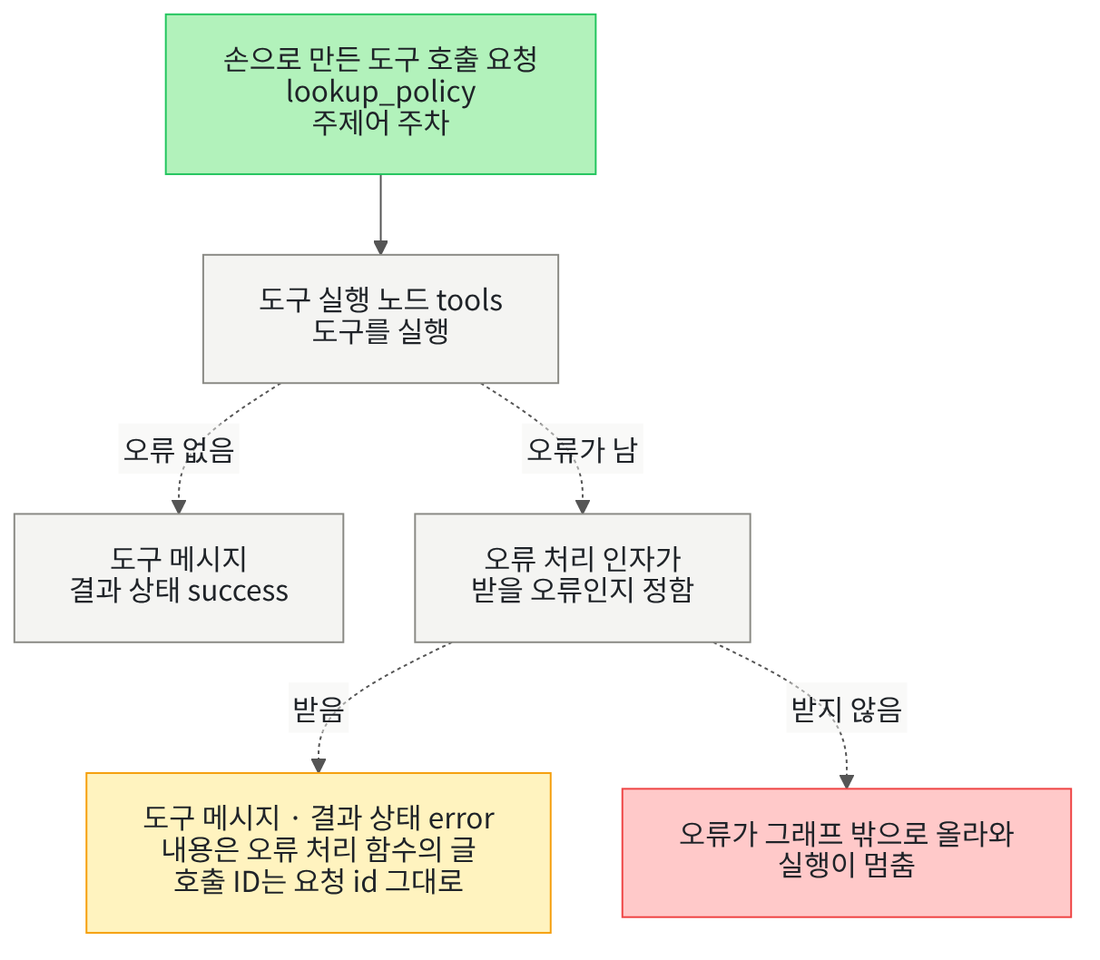

## 1. 준비

01절에서는 도구 실행 노드(`ToolNode`)가 도구 호출 요청을 실행하고 도구 메시지를 더했습니다.
그때 도구는 한 번도 오류를 내지 않았습니다.
이 절은 도구가 오류를 낼 때 도구 실행 노드가 무엇을 하는지 봅니다.
제목의 `ToolMessage`는 Ch 19 05절에서 본 도구 메시지입니다.

첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langchain: 1.4.0`·`langchain-core: 1.6.2`가 보입니다.
출력 줄 `langchain-openai: 1.6.0`과 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
그래프·메시지·도구 이름은 01절과 같습니다.
Ch 19 06절의 오류 이름 `ToolException`을 하나 더 가져오고, 쓰는 곳은 8절입니다.
도구 파일에서는 Ch 19 함수 `show_messages`와 `tool_call_names`를 가져옵니다.

In [2]:
# 01절 이름에 Ch 19 06절 오류 이름 하나를 더하고, 도구 파일 함수 둘을 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict

from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, AnyMessage, HumanMessage
from langchain.tools import ToolException, tool
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from graph_tools import show_messages, tool_call_names

print("01절에 더해 가져온 이름:", "ToolException")

01절에 더해 가져온 이름: ToolException


**결과 읽기** — 출력 줄 `01절에 더해 가져온 이름: ToolException`이 보입니다.

앞에서 배운 함수는 `graph_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `tool_call_names`는 Ch 19 04절, 함수 `show_messages`는 Ch 19 06절에서 배웠습니다.
두 함수는 01절에서 쓴 도구 파일의 함수 그대로입니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 도구 메시지를 읽고 할 일이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 규정 자료와 도구

자료와 도구는 01절과 같은 코드입니다.
다음 셀은 01절처럼 주제어를 키, 규정 글을 값으로 둔 딕셔너리를 만듭니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
이 셀은 01절 셀과 글자까지 같습니다.

다음 셀은 01절과 같은 도구 `lookup_policy`를 만듭니다.
코드는 01절과 같고, 오류를 내는 줄 위 주석 한 줄만 이 절에 맞게 고쳤습니다.
딕셔너리에 없는 주제어면 Ch 16 01절처럼 `raise`로 `ValueError`를 냅니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 절은 이 오류를 그래프 안에서 다룹니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
Ch 19 06절의 도구는 오류 이름으로 `ToolException`을 썼습니다.
이 도구가 내는 오류는 `ValueError`이고, 이 차이는 7절에서 다시 봅니다.

다음 셀은 도구의 입력 형식을 보고, 없는 주제어 `"주차"`로 도구를 직접 불러 봅니다.
실행 전에 예상해 봅니다.
입력 형식의 자료형이 글자뿐이면, `"주차"`도 입력 검사를 지나 몸통에서 오류가 날 것입니다.
이 셀만 그 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [7]:
# 입력 형식을 보고, 없는 주제어로 도구를 직접 불러 봅니다(이 셀만 오류를 받아 출력합니다)
print("입력 형식:", lookup_policy.args)
try:
    lookup_policy.invoke({"topic": "주차"})
except ValueError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

입력 형식: {'topic': {'title': 'Topic', 'type': 'string'}}
받은 오류: ValueError
오류 글: 지원하지 않는 주제: 주차


**결과 읽기** — 라벨 `입력 형식:` 뒤 딕셔너리에서 인자 `topic`의 자료형은 `string`뿐입니다.
Ch 19 02절의 고를 수 있는 값(`Literal`)처럼, 넣을 수 있는 값을 정해 두지 않았습니다.
그래서 `"주차"`도 입력 검사를 지났고, 출력 줄 `받은 오류: ValueError`처럼 몸통에서 오류가 났습니다.
라벨 `오류 글:` 뒤 `지원하지 않는 주제: 주차`는 `raise` 줄에 적은 글입니다.

Ch 2 05절에서 본 것처럼, 오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.
그래프 안에서 이 도구가 오류를 내면 어떻게 되는지는 6절에서 봅니다.

다음 셀은 01절처럼 도구 목록을 모델에게 알려 줍니다.

In [8]:
# 도구 목록을 모델에게 알려 줍니다(Ch 19 04절 bind_tools, 요청은 아직 보내지 않음)
tools = [lookup_policy]
# 한 응답에 도구 호출 요청을 하나까지만 받게 합니다(Ch 19 06절과 같은 값)
bound_model = model.bind_tools(tools, parallel_tool_calls=False)
print("실어 보낼 명세 수:", len(bound_model.kwargs["tools"]))
print("여럿 담기:", bound_model.kwargs["parallel_tool_calls"])

실어 보낼 명세 수: 1
여럿 담기: False


**결과 읽기** — 출력 줄 `실어 보낼 명세 수: 1`과 `여럿 담기: False`는 01절과 같습니다.
이 셀은 01절 셀과 글자까지 같고, 아직 모델 요청은 보내지 않았습니다.

## 4. 상태 형식·노드·그래프

상태 형식과 모델 노드, 이름표 표는 01절 셀과 글자까지 같습니다.
다음 셀은 메시지 칸과 실행 흔적 칸에 규칙을 적은 상태 형식 `AgentState`를 만듭니다.

In [9]:
# 메시지 칸과 실행 흔적 칸에 각각 규칙을 적은 상태 형식을 만듭니다(Ch 13 04절 모양)
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 구성이 01절과 같아서, 이름도 `AgentState` 그대로 씁니다.

다음 셀은 01절의 모델 노드 함수입니다.
메시지 칸 전체를 도구를 알려 준 모델에 보내고, 응답 하나와 노드 이름 `"model"`만 냅니다.

In [10]:
# 메시지 칸 전체를 도구를 알려 준 모델에 보내고, 응답 하나와 노드 이름만 냅니다
def call_model(state):
    response = bound_model.invoke(state["messages"])
    return {"messages": [response], "trace": ["model"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드를 한 번 지날 때마다 모델 요청이 한 번 나갑니다.
그래서 01절처럼 실행 흔적 칸의 `model` 수가 모델 요청 수입니다.

다음 셀은 도구 조건 함수의 이름표 둘을 갈 곳에 잇는 이름표 표입니다.

In [11]:
# 도구 조건 함수의 이름표 둘을 실제로 갈 곳에 잇는 이름표 표를 만듭니다(Ch 13 03절)
path_map = {"tools": "tools", END: END}
print("이름표와 갈 곳을 이은 표:")
for label in path_map:
    print(label, "->", path_map[label])

이름표와 갈 곳을 이은 표:
tools -> tools
__end__ -> __end__


**결과 읽기** — 라벨 줄 아래 두 줄 `tools -> tools`와 `__end__ -> __end__`는 01절과 같습니다.

다음 셀은 도구 실행 노드 하나를 받아 그래프를 만드는 함수입니다.
이 절은 도구 실행 노드의 설정만 바꿔 가며 같은 그래프를 두 번 만들기 때문입니다.
그래프 모양은 01절과 같고, 시작 엣지만 도구 실행 노드로 옮겼습니다.
첫 상태에 손으로 만든 도구 호출 요청을 넣고, 그 요청부터 실행하려는 것입니다.
상태 형식·모델 노드·이름표 표는 앞 셀에서 만든 것을 그대로 씁니다.

In [12]:
# 도구 실행 노드 하나를 받아, 01절 그래프에서 시작 엣지만 옮긴 그래프를 만들어 내놓습니다
def build_graph(tool_node):
    builder = StateGraph(AgentState)
    builder.add_node("model", call_model)
    builder.add_node("tools", tool_node)
    # 첫 상태에 넣은 도구 호출 요청부터 실행하려고, 시작 엣지를 도구 실행 노드로 둡니다
    builder.add_edge(START, "tools")
    builder.add_conditional_edges("model", tools_condition, path_map)
    builder.add_edge("tools", "model")
    return builder.compile()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_graph`는 받은 도구 실행 노드를 이름 `"tools"`로 등록하고, 컴파일한 그래프를 내놓습니다.
조건부 엣지와 엣지 `tools → model`은 01절과 같은 자리입니다.
다른 곳은 시작 엣지 `builder.add_edge(START, "tools")` 한 줄뿐입니다.
모델이 요청을 쓰는 보통 그래프는 01절처럼 시작 엣지가 모델 노드로 가고, 05절 실습도 그 모양을 씁니다.

## 5. 손으로 만든 도구 호출 요청

01절 5절에서는 도구 조건 함수에 넣어 보려고 응답을 손으로 만들었습니다.
이 절도 같은 모양으로, 도구 호출 요청 하나를 담은 응답을 손으로 만듭니다.
모델이 주차 규정을 찾아 달라는 요청을 보냈다고 치는 것입니다.
모델이 이런 요청을 언제 보내는지가 아니라, 요청이 온 뒤의 일을 보려는 것입니다.

In [13]:
# 주차 규정을 찾아 달라는 도구 호출 요청 하나를 손으로 만들고, 질문과 함께 첫 상태에 넣습니다
park_call = {"name": "lookup_policy", "args": {"topic": "주차"}, "id": "hand_call_park", "type": "tool_call"}
park_request = AIMessage(content="", tool_calls=[park_call])
park_question = "자료실 주차 규정을 알려 주세요."
park_state = {"messages": [HumanMessage(content=park_question), park_request], "trace": []}
print("손으로 만든 응답의 도구 호출 요청:", tool_call_names(park_request))
print("요청의 인자:", park_call["args"])
print("요청의 id:", park_call["id"])

손으로 만든 응답의 도구 호출 요청: ['lookup_policy']
요청의 인자: {'topic': '주차'}
요청의 id: hand_call_park


**결과 읽기** — 출력 줄 `손으로 만든 응답의 도구 호출 요청: ['lookup_policy']`입니다.
출력 줄 `요청의 인자: {'topic': '주차'}`와 `요청의 id: hand_call_park`도 보입니다.
이 요청은 우리가 손으로 만든 것이고, 모델이 쓴 요청이 아닙니다.
첫 상태의 메시지 칸에는 질문과 이 응답, 두 메시지가 들어 있습니다.

## 6. 기본값 그대로 실행하기 (Before)

먼저 01절처럼 도구 목록만 넘겨 도구 실행 노드를 만듭니다.
오류를 어떻게 다룰지 정하는 인자를 주지 않았으니, 도구 실행 노드는 기본값으로 움직입니다.
다음 셀은 이 노드로 그래프를 만들고, 그래프가 스스로 그린 구조 문자열을 봅니다.

In [14]:
# Before: 01절처럼 도구 목록만 넘긴 도구 실행 노드로 그래프를 만들고, 구조 문자열을 봅니다
default_node = ToolNode(tools)
before_graph = build_graph(default_node)
before_structure = before_graph.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(before_structure)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> tools;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래 화살표 줄 넷을 봅니다.
줄 `__start__ --> tools;`가 01절과 다른 시작 엣지입니다.
줄 `tools --> model;`은 01절의 되돌아가는 엣지이고, 여기서는 도구 실행 노드 다음 차례를 정합니다.
줄 `model -.-> tools;`와 `model -.-> __end__;`는 01절과 같은 조건부 엣지의 두 갈래입니다.

다음 셀은 5절의 첫 상태로 이 그래프를 실행합니다.
실행 전에 예상해 봅니다.
도구 실행 노드가 주차 요청을 실행하면, 도구가 3절처럼 `ValueError`를 낼 것입니다.
이 셀만 그 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [15]:
# Before 그래프를 주차 요청이 든 첫 상태로 실행합니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    before_graph.invoke(park_state)
except ValueError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ValueError
오류 글: 지원하지 않는 주제: 주차


**결과 읽기** — 출력 줄 `받은 오류: ValueError`처럼 도구의 오류가 그래프 밖 셀까지 올라왔습니다.
라벨 `오류 글:` 뒤 글은 3절과 같은 `지원하지 않는 주제: 주차`입니다.
그래프 실행은 도구 실행 노드에서 멈췄고, 메서드 `invoke`는 실행 결과를 내놓지 못했습니다.
모델 노드는 도구 실행 노드 다음 차례라, 이 실행에서는 모델 요청도 나가지 않았습니다.

오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.
모델은 주차 규정을 찾지 못했다는 것을 듣지 못하고, 답도 적지 못합니다.
이것이 Before의 결함입니다.
설치한 langgraph-prebuilt 1.1.0 소스에서도 기본값은 `ValueError`를 받지 않고 다시 올립니다.

## 7. 오류 처리 함수로 실행하기 (After)

이제 결함을 고칩니다.
도구 실행 노드를 만들 때 인자 `handle_tool_errors`에 오류 처리 함수를 넘깁니다.
오류 처리 인자는 도구를 실행하다 난 오류 가운데, 무엇을 받아 도구 메시지로 바꿀지 정하는 인자입니다.
자료실로 치면 서고가 쪽지대로 찾지 못했을 때, 상자를 멈출지 빈 카드를 실어 올릴지 정하는 규칙입니다.
코드에서는 `ToolNode(tools, handle_tool_errors=handle_policy_error)` 한 줄입니다.

이 인자는 Ch 19 06절 도구 속성 `handle_tool_error`와 이름 끝 한 글자가 다릅니다.
06절의 오류 담기 설정(단수)은 도구 하나에 붙고, `ToolException`만 받았습니다.
이 절의 오류 처리 인자(복수)는 도구 실행 노드에 붙고, 받을 오류 종류를 우리가 정합니다.
이 절의 도구는 `ValueError`를 내므로, 06절의 도구 속성으로는 받을 수 없습니다.

다음 셀은 오류 처리 함수입니다.
오류 처리 함수는 도구 실행 노드가 넘긴 오류 하나를 받아, 도구 메시지에 담을 글을 내놓는 함수입니다.
첫 매개변수 뒤 `: ValueError`는 받을 오류 표시입니다.
도구 실행 노드는 이 표시를 읽고, `ValueError`일 때만 이 함수에 오류를 넘깁니다.
Ch 19 01절 `@tool` 함수의 `: str`처럼, 이 표시도 라이브러리가 읽는 값입니다.

In [16]:
# 도구 실행 노드가 넘긴 ValueError 하나로, 도구 메시지에 담을 안내 글을 만들어 내놓습니다
def handle_policy_error(error: ValueError):
    # 첫 매개변수의 표시 ValueError를 도구 실행 노드가 읽고, 이 종류의 오류만 이 함수에 넘깁니다
    reason = str(error)
    # 무엇이 잘못됐는지와, 이 도구로 찾을 수 있는 주제어를 함께 적습니다
    return "규정을 찾지 못했습니다(" + reason + "). 이 도구로 찾을 수 있는 주제어는 대출, 운영, 연체입니다."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `handle_policy_error`는 받은 오류의 글을 `str`로 꺼내 안내 글 가운데에 넣습니다.
안내 글에는 무엇이 잘못됐는지와, 이 도구로 찾을 수 있는 주제어를 함께 적었습니다.
Ch 19 06절 오류 글처럼, 모델이 읽고 다음 할 일을 정할 수 있게 하려는 것입니다.

다음 셀은 이 함수를 그래프 없이 한 번 불러, 어떤 글을 내놓는지 봅니다.
3절 도구와 같은 글을 담은 `ValueError`를 직접 만들어 넣습니다.

In [17]:
# 3절과 같은 글의 ValueError를 만들어, 도구 실행 노드 없이 오류 처리 함수에 넣어 봅니다
sample_error = ValueError("지원하지 않는 주제: 주차")
guide_text = handle_policy_error(sample_error)
print("내놓은 글:", guide_text)

내놓은 글: 규정을 찾지 못했습니다(지원하지 않는 주제: 주차). 이 도구로 찾을 수 있는 주제어는 대출, 운영, 연체입니다.


**결과 읽기** — 라벨 `내놓은 글:` 뒤에 안내 글 한 줄이 보입니다.
괄호 안 `지원하지 않는 주제: 주차`가 오류의 글이고, 괄호 뒤 문장이 주제어 안내입니다.
도구 실행 노드는 받은 오류를 이 함수에 넣고, 내놓은 글을 도구 메시지의 내용으로 씁니다.

다음 셀은 이 함수를 넘긴 도구 실행 노드로, 같은 함수 `build_graph`로 그래프를 만듭니다.
6절과 다른 곳은 도구 실행 노드를 만드는 줄 하나뿐입니다.

In [18]:
# After: 오류 처리 함수를 넘긴 도구 실행 노드로, 같은 함수 build_graph로 그래프를 만듭니다
policy_node = ToolNode(tools, handle_tool_errors=handle_policy_error)
after_graph = build_graph(policy_node)
after_structure = after_graph.get_graph().draw_mermaid()
print("만든 것의 종류:", type(policy_node).__name__)
print("구조 문자열이 Before와 같은가:", after_structure == before_structure)

만든 것의 종류: ToolNode
구조 문자열이 Before와 같은가: True


**결과 읽기** — 출력 줄 `만든 것의 종류: ToolNode`입니다.
출력 줄 `구조 문자열이 Before와 같은가: True`로, 그래프 모양은 Before와 같습니다.
달라진 것은 도구 실행 노드의 오류 처리 인자 하나입니다.

다음 셀은 5절의 같은 첫 상태로 After 그래프를 실행합니다.
실행 전에 예상해 봅니다.
이번에는 오류가 도구 메시지가 되어, 도구 실행 노드 다음 차례인 모델 노드로 갈 것입니다.
모델 노드를 지나면 모델 요청이 한 번 나갑니다.

In [19]:
# After 그래프를 같은 첫 상태로 실행합니다(모델 노드를 지날 때마다 모델 요청 1번)
after_result = after_graph.invoke(park_state)
print("실행 흔적 칸:", after_result["trace"])
print("메시지 칸:")
show_messages(after_result["messages"])

실행 흔적 칸: ['model']
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: error | 내용: 규정을 찾지 못했습니다(지원하지 않는 주제: 주차). 이 도구로 찾을 수 있는 주제어는 대출, 운영, 연체입니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['model']`로 모델 노드를 한 번 지났고, 모델 요청은 1번입니다.
라벨 줄 `메시지 칸:` 아래 셋째 줄이 도구 메시지이고, 결과 상태가 `error`입니다.
그 내용은 앞에서 오류 처리 함수를 그래프 없이 불렀을 때 내놓은 글과 같습니다.
넷째 줄 `AIMessage | 도구 호출 요청: []`는 모델이 도구 메시지를 읽고 도구 없이 적은 응답입니다.
Before에서 그래프를 멈춘 같은 요청이, 이번에는 도구 메시지가 되어 모델 노드까지 갔습니다.

모델이 다시 도구를 요청할지는 모델이 정하는 값이라, 실행한 때에 따라 달라질 수 있습니다.
노트북 밖에서 같은 흐름을 다섯 번 보냈을 때는 다섯 번 모두 이 차례였습니다.

다음 셀은 셋째 메시지인 도구 메시지를 따로 봅니다.

In [20]:
# 셋째 메시지(도구 메시지)의 종류·결과 상태·호출 ID를 봅니다
error_message = after_result["messages"][2]
print("셋째 메시지의 종류:", type(error_message).__name__)
print("결과 상태:", error_message.status)
print("호출 ID:", error_message.tool_call_id)
print("요청 id와 같은가:", error_message.tool_call_id == park_call["id"])
# 두 값은 모델이 아니라 도구 실행 노드가 정하므로 매번 같아야 합니다
assert error_message.status == "error", "받은 오류는 결과 상태가 error인 도구 메시지가 되어야 합니다"
assert error_message.tool_call_id == park_call["id"], "도구 메시지에는 요청 id가 옮겨져야 합니다"

셋째 메시지의 종류: ToolMessage
결과 상태: error
호출 ID: hand_call_park
요청 id와 같은가: True


**결과 읽기** — 출력 줄 `셋째 메시지의 종류: ToolMessage`와 `결과 상태: error`입니다.
출력 줄 `호출 ID: hand_call_park`는 5절 손으로 만든 요청의 id 그대로입니다.
출력 줄 `요청 id와 같은가: True`로, 도구 실행 노드가 오류 때도 호출 ID를 옮겨 적었습니다.
Ch 19 05절의 같은 색 집게처럼, 이 도구 메시지가 어느 요청의 결과인지 알려 줍니다.
두 값은 도구 실행 노드가 정하므로, 셀 끝 `assert`로 확인했습니다.

다음 셀은 메시지 칸의 마지막 응답을 봅니다.

In [21]:
# 메시지 칸의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
last_message = after_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(last_message.tool_calls))
print("답 글:")
print(last_message.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
죄송하지만, 현재 제가 확인할 수 있는 자료실 규정은 **대출, 운영, 연체** 주제만입니다.  
**주차 규정**은 이 자료로는 찾을 수 없습니다.

원하시면 대신 아래 중 하나를 알려드릴 수 있어요:
- 자료실 **대출 규정**
- 자료실 **운영 규정**
- 자료실 **연체 규정**


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 도구 메시지를 읽고 쓴 답입니다.

답 글의 문장은 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.
이번 실행에서는 답 글이 주차 규정은 이 자료로는 찾을 수 없다고 적고, 대출·운영·연체 규정을 대신 권했습니다.
답 글의 별표 두 개(`**`)는 모델이 굵은 글씨를 표시하려고 붙인 기호입니다.

## 8. 값 바꿔 보기 · 인자 이름이 틀린 요청

바꿀 값은 손으로 만든 도구 호출 요청 하나입니다.
주제어 값은 맞지만, 인자 이름을 `topic` 대신 `주제`로 잘못 적은 요청으로 바꿉니다.
질문도 이 요청에 맞게 01절 7절의 대출 질문으로 둡니다.
도구 실행 노드 둘과 그래프 둘은 6·7절에서 만든 것을 그대로 씁니다.

In [22]:
# 바꿀 값: 인자 이름을 topic 대신 주제로 잘못 적은 요청을 손으로 만들어 첫 상태에 넣습니다
key_call = {"name": "lookup_policy", "args": {"주제": "대출"}, "id": "hand_call_key", "type": "tool_call"}
key_request = AIMessage(content="", tool_calls=[key_call])
key_question = "자료실에서 일반 도서를 며칠 빌릴 수 있나요?"
key_state = {"messages": [HumanMessage(content=key_question), key_request], "trace": []}
print("요청의 인자:", key_call["args"])
arg_names = list(lookup_policy.args.keys())
print("입력 형식의 인자 이름:", arg_names)

요청의 인자: {'주제': '대출'}
입력 형식의 인자 이름: ['topic']


**결과 읽기** — 출력 줄 `요청의 인자: {'주제': '대출'}`입니다.
출력 줄 `입력 형식의 인자 이름: ['topic']`과 견주면, 꼭 채울 인자 `topic`이 빠졌습니다.
이 요청은 도구 몸통까지 가지 못하고, Ch 19 02절의 입력 검사에서 걸릴 것입니다.

다음 셀은 이 첫 상태로 After 그래프를 실행합니다.
도구 실행 노드는 입력 검사에서 걸린 오류를 `ToolInvocationError`라는 이름으로 감쌉니다.
이 오류는 Ch 19 06절 `ToolException`의 한 종류라, 셀은 그 이름으로 받습니다.
실행 전에 예상해 봅니다.
이 오류는 `ValueError`가 아니니, 오류 처리 함수로 가지 않고 그래프 밖으로 올라올 것입니다.

In [23]:
# 인자 이름이 틀린 요청을 After 그래프로 실행합니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    after_graph.invoke(key_state)
except ToolException as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: ToolInvocationError
오류 글:
Error invoking tool 'lookup_policy' with kwargs {'주제': '대출'} with error:
 topic: Field required
 Please fix the error and try again.


**결과 읽기** — 출력 줄 `받은 오류: ToolInvocationError`처럼 오류가 그래프 밖 셀까지 올라왔습니다.
라벨 줄 `오류 글:` 아래 영어 글의 `topic: Field required`는 꼭 채울 인자가 없다는 뜻입니다.
7절에서 도구 메시지를 만든 같은 노드가, 요청만 바꾸자 그래프를 멈췄습니다.

이 출력은 표시가 `ValueError`인 함수를 넘긴 노드가 이 오류를 받지 않았다는 것까지 보여 줍니다.
받을 오류 표시가 받는 오류 종류를 정한다는 것은 설치판 소스와 노트북 밖 확인이 근거입니다.
표시를 뺀 함수를 넘기면 이 오류도 받았지만, 노트북에서는 실행하지 않았습니다.

다음 셀은 같은 요청을 6절 Before 그래프, 곧 기본값 도구 실행 노드로 실행합니다.
실행 전에 예상해 봅니다.
설치판 소스에서 기본값은 입력 검사에서 걸린 오류만 받아 도구 메시지로 바꿉니다.
그렇다면 이번에는 도구 메시지가 모델 노드로 가고, 모델 요청이 나갈 것입니다.

In [24]:
# 같은 요청을 Before 그래프, 곧 기본값 도구 실행 노드로 실행합니다(모델 요청이 나갑니다)
key_result = before_graph.invoke(key_state)
print("실행 흔적 칸:", key_result["trace"])
print("메시지 칸:")
show_messages(key_result["messages"])

실행 흔적 칸: ['model', 'model']
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: error | 내용: Error invoking tool 'lookup_policy' with kwargs {'주제': '대출'} with error:
 topic: Field required
 Please fix the error and try again.
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['model', 'model']`로 모델 노드를 두 번 지났습니다.
라벨 줄 `메시지 칸:` 아래 첫 도구 메시지는 결과 상태가 `error`입니다.
그 내용은 앞 셀과 같은 영어 오류 글입니다.
둘째 도구 메시지는 결과 상태가 `success`이고, 마지막 줄 `AIMessage | 도구 호출 요청: []`로 끝났습니다.
Before에서 `ValueError`로 멈춘 기본값 노드가, 입력 검사에서 걸린 오류는 도구 메시지로 바꿨습니다.

Ch 19 07절은 설치판 소스로 「값 검사 오류는 흐름을 멈춘다」고 적었습니다.
그것은 우리가 쓴 `for` 루프와 도구 속성 이야기이고, 도구 실행 노드의 기본값은 다르게 움직입니다.

다음 셀은 첫 도구 메시지와, 그 뒤 응답이 다시 보낸 요청을 봅니다.

In [25]:
# 셋째 메시지(첫 도구 메시지)의 결과 상태·호출 ID와, 넷째 메시지(응답)의 도구 호출 요청을 봅니다
key_error = key_result["messages"][2]
print("셋째 메시지의 결과 상태:", key_error.status)
print("요청 id와 같은가:", key_error.tool_call_id == key_call["id"])
retry_response = key_result["messages"][3]
for call in retry_response.tool_calls:
    print("넷째 메시지가 다시 보낸 요청의 인자:", call["args"])
# 결과 상태는 도구 실행 노드가 정하는 값이라 매번 같아야 합니다
assert key_error.status == "error", "입력 검사에서 걸린 오류도 결과 상태가 error인 도구 메시지가 되어야 합니다"

셋째 메시지의 결과 상태: error
요청 id와 같은가: True
넷째 메시지가 다시 보낸 요청의 인자: {'topic': '대출'}


**결과 읽기** — 출력 줄 `셋째 메시지의 결과 상태: error`와 `요청 id와 같은가: True`입니다.
기본값 노드도 오류를 담은 도구 메시지에 요청 id를 옮겨 적었습니다.
출력 줄 `넷째 메시지가 다시 보낸 요청의 인자: {'topic': '대출'}`로, 모델이 인자 이름을 고쳤습니다.
셀 끝 `assert`는 도구 실행 노드가 정하는 결과 상태에만 걸었습니다.

인자 이름을 고쳐 다시 요청한 것은 모델이 정한 일이라, 실행한 때에 따라 달라질 수 있습니다.
노트북 밖에서 같은 흐름을 다섯 번 보냈을 때도, 다섯 번 모두 인자 이름을 `topic`으로 고쳐 다시 요청했습니다.

## 9. 네 실행 견주기

같은 그래프에 요청 둘과 도구 실행 노드 설정 둘을 넣은 네 실행은 아래와 같았습니다.

- 주차 요청과 기본값 노드(Before)는 `ValueError`로 멈췄고, 모델 요청은 없었습니다.
- 주차 요청과 오류 처리 함수 노드(After)는 결과 상태 `error`인 도구 메시지를 만들고, 모델 요청이 1번이었습니다.
- 인자 이름이 틀린 요청과 오류 처리 함수 노드는 `ToolInvocationError`로 멈췄습니다.
- 인자 이름이 틀린 요청과 기본값 노드는 도구 메시지를 만들고, 모델 요청이 2번이었습니다.

## 정리

1. 도구 실행 노드의 기본값은 도구가 낸 `ValueError`를 그대로 올려, 그래프 실행이 멈췄습니다.
2. 오류 처리 함수를 넘기자 같은 오류가 결과 상태 `error`인 도구 메시지가 되어 모델 노드로 갔습니다.
3. 받을 오류 표시 `ValueError`에 맞지 않는 입력 검사 오류는 오류 처리 함수로 가지 않았습니다.

03절에서는 그래프가 도구 쪽을 되풀이하는 횟수의 한도와, 흐름을 끝내는 조건을 봅니다.